In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

       STARBUCKS EXPLORATORY DATA ANALYSIS


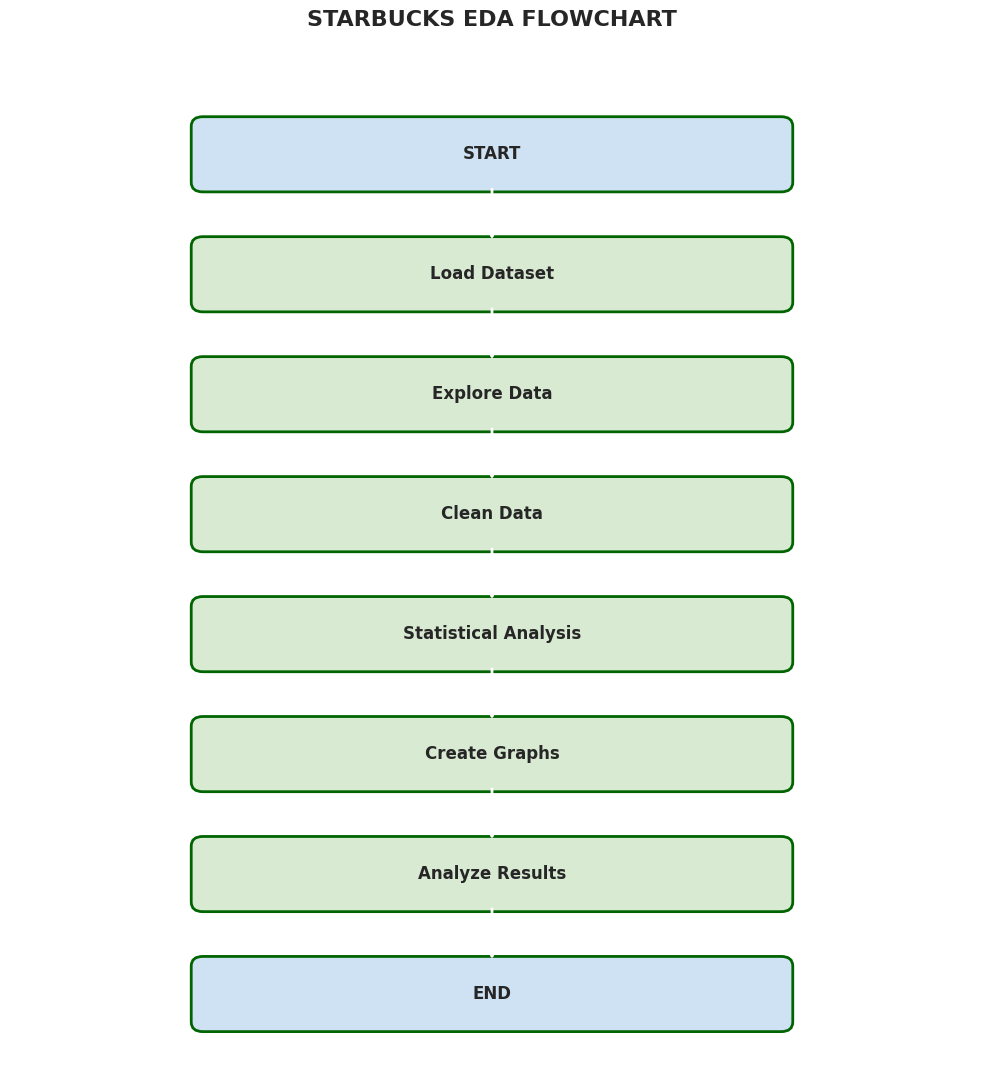


CSV files found: 0

Using DEMONSTRATION data for graphs only.
Attach your real Starbucks CSV for actual analysis.

DATASET SHAPE: (15, 7)

FIRST FIVE ROWS:


,Beverage_category,Beverage,Calories,Sugars_g,Caffeine_mg,Protein_g,Fat_g
0,Coffee,Brewed Coffee,5,0,180,0,0
1,Coffee,Latte,190,18,150,13,7
2,Tea,Green Tea,0,0,25,0,0
3,Tea,Chai Tea,120,21,95,4,2
4,Frappuccino,Mocha Frappuccino,330,45,110,5,15



COLUMN NAMES:
['Beverage_category', 'Beverage', 'Calories', 'Sugars_g', 'Caffeine_mg', 'Protein_g', 'Fat_g']

DATA TYPES:
Beverage_category    object
Beverage             object
Calories              int64
Sugars_g              int64
Caffeine_mg           int64
Protein_g             int64
Fat_g                 int64
dtype: object

MISSING VALUES:


,Missing Values
Beverage_category,0
Beverage,0
Calories,0
Sugars_g,0
Caffeine_mg,0
Protein_g,0
Fat_g,0



DUPLICATE ROWS: 0

STATISTICAL SUMMARY:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Beverage_category,15,4,Coffee,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Beverage,15,15,Brewed Coffee,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Calories,15.0,NaN,NaN,NaN,119.0,123.33462,0.0,7.5,120.0,200.0,330.0
Sugars_g,15.0,NaN,NaN,NaN,14.8,17.009241,0.0,0.0,12.0,26.5,45.0
Caffeine_mg,15.0,NaN,NaN,NaN,91.666667,48.427658,0.0,75.0,90.0,120.0,180.0
Protein_g,15.0,NaN,NaN,NaN,3.8,4.262796,0.0,0.5,3.0,5.0,13.0
Fat_g,15.0,NaN,NaN,NaN,4.266667,4.992375,0.0,0.0,2.0,7.0,15.0



DETECTED COLUMNS
Calories: Calories
Sugar: Sugars_g
Caffeine: Caffeine_mg
Category: Beverage_category
Drink: Beverage_category
Protein: Protein_g


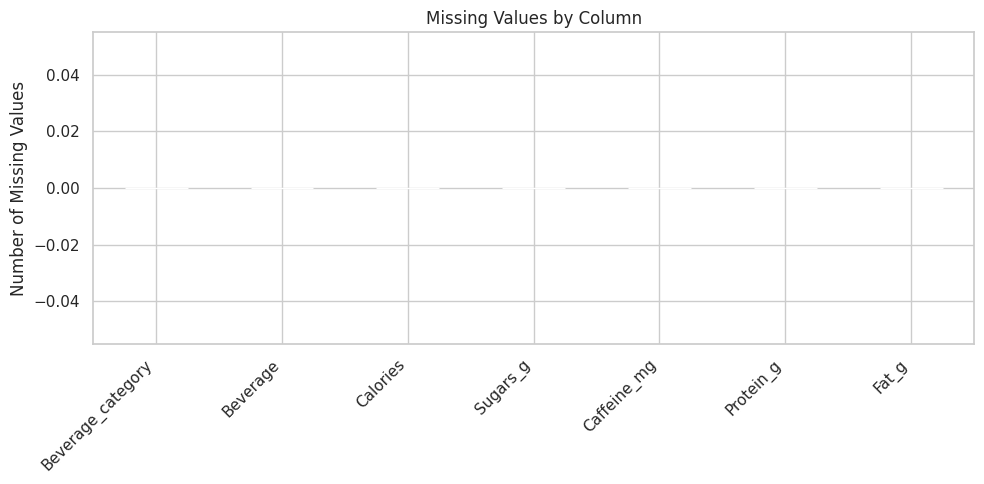

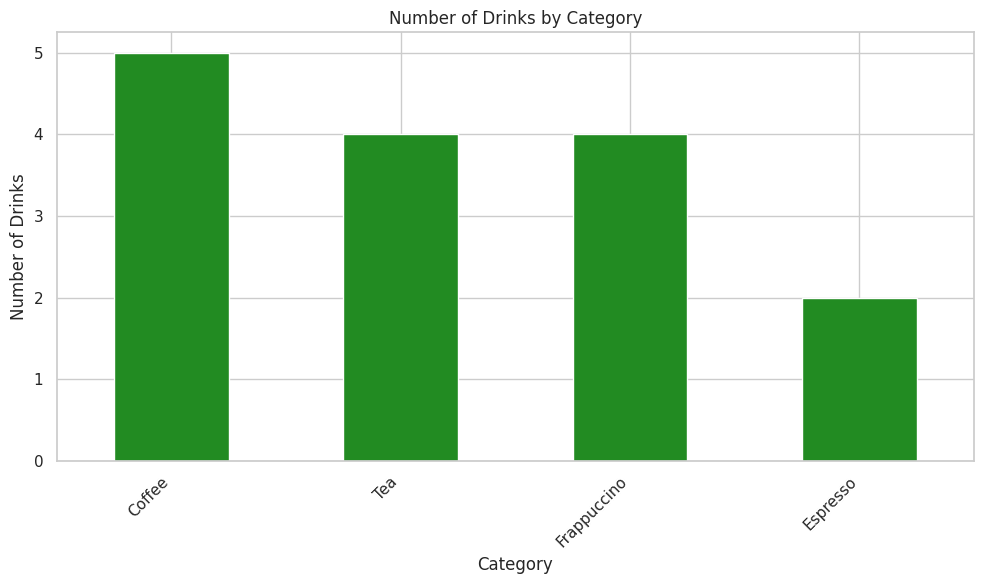

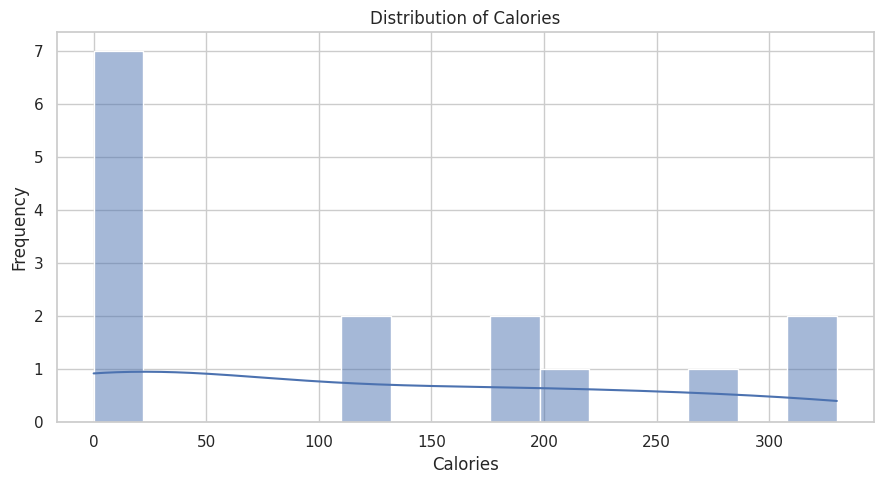

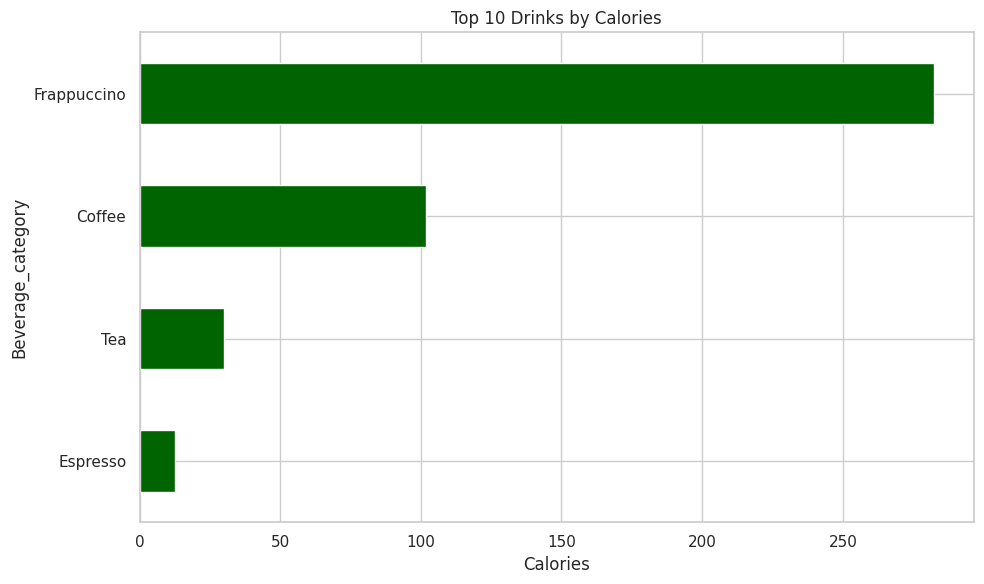

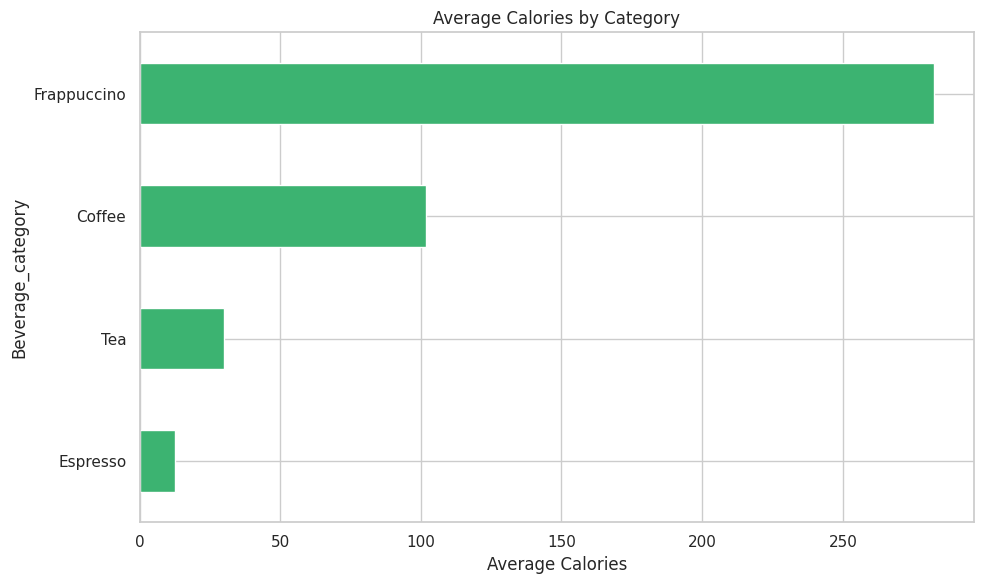

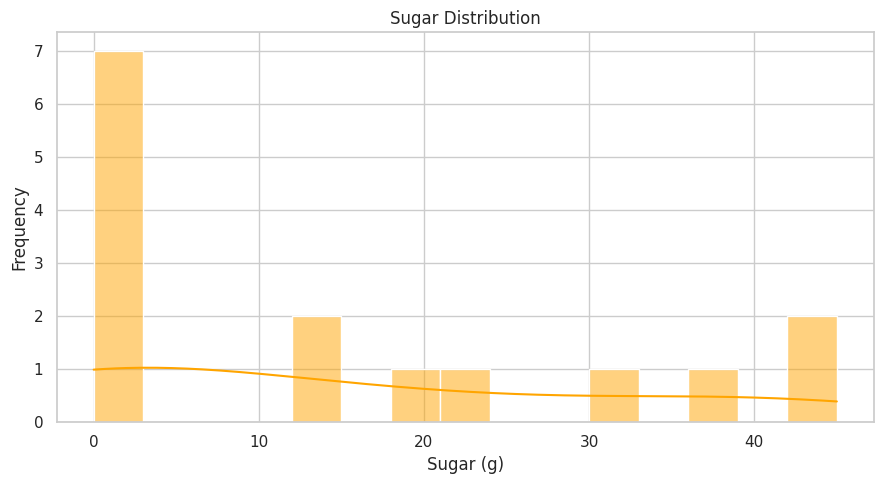

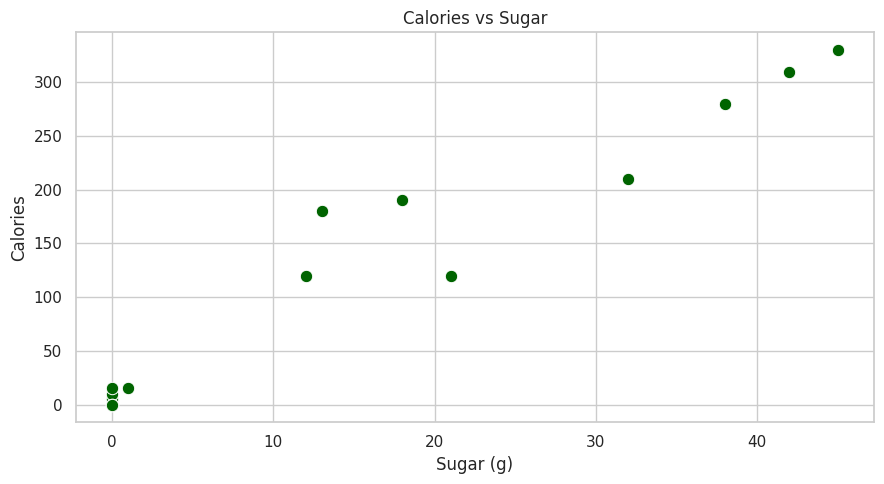

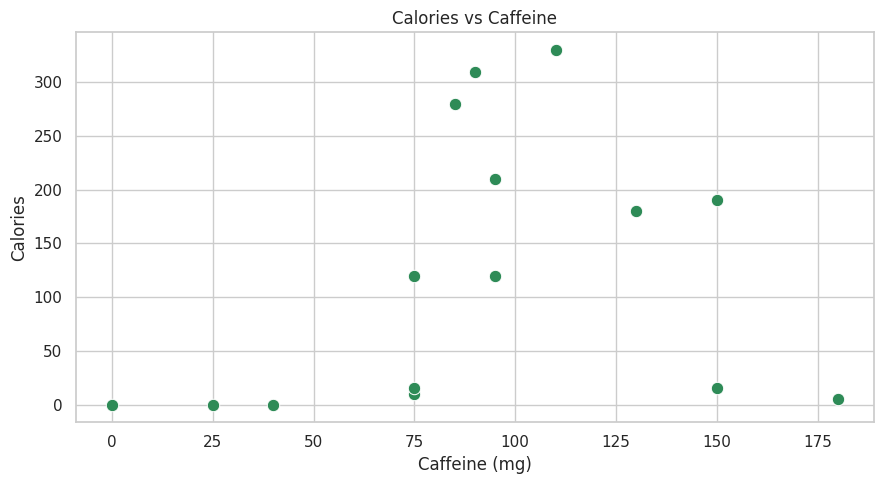

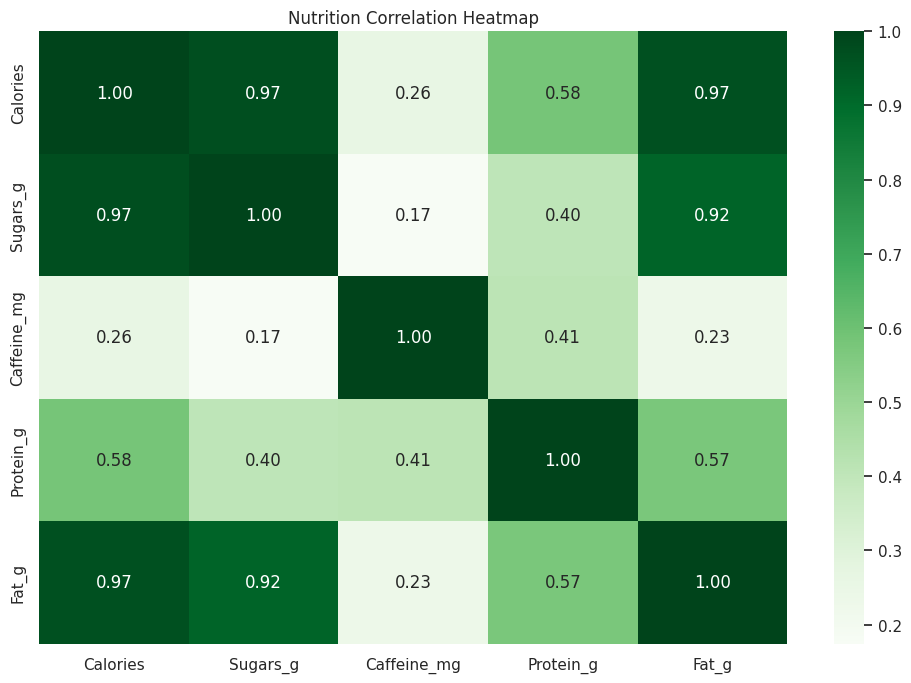

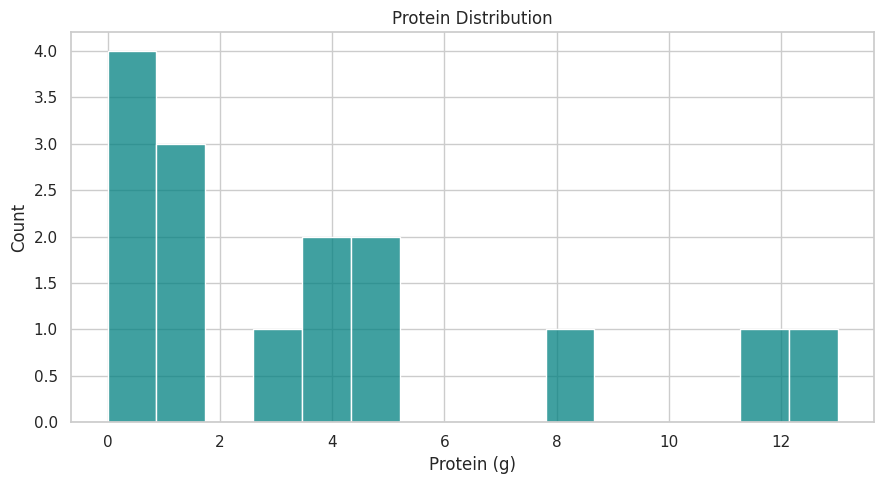


              FINAL EDA FINDINGS
Rows: 15
Columns: 7
Numeric variables: ['Calories', 'Sugars_g', 'Caffeine_mg', 'Protein_g', 'Fat_g']

Average calories: 119.0
Minimum calories: 0
Maximum calories: 330

Average sugar: 14.8

Average caffeine: 91.67
Calories-sugar correlation: 0.972

Average calories by category:


,Average Calories
Beverage_category,
Frappuccino,282.5
Coffee,102.0
Tea,30.0
Espresso,12.5



EDA FINISHED!
REMINDER: Current results use demonstration data,
not the actual Starbucks menu dataset.


In [ ]:

# =========================================================
# STARBUCKS EDA PROJECT
# FLOWCHART + GRAPHS + DATA ANALYSIS
# Kaggle Notebook - Run in ONE cell
# =========================================================

import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import FancyBboxPatch
from IPython.display import display

sns.set_theme(style="whitegrid")

print("=" * 55)
print("       STARBUCKS EXPLORATORY DATA ANALYSIS")
print("=" * 55)

# =========================================================
# 1. FLOWCHART - ALWAYS DISPLAY
# =========================================================

fig, ax = plt.subplots(figsize=(10, 11))
ax.set_xlim(0, 10)
ax.set_ylim(0, 13)
ax.axis("off")

steps = [
    "START",
    "Load Dataset",
    "Explore Data",
    "Clean Data",
    "Statistical Analysis",
    "Create Graphs",
    "Analyze Results",
    "END"
]

ys = np.linspace(11.5, 1, len(steps))

for i, (step, y) in enumerate(zip(steps, ys)):
    box = FancyBboxPatch(
        (2, y - 0.35), 6, 0.7,
        boxstyle="round,pad=0.12",
        facecolor="#D9EAD3" if i not in [0, 7] else "#CFE2F3",
        edgecolor="darkgreen",
        linewidth=2
    )
    ax.add_patch(box)
    ax.text(5, y, step, ha="center", va="center",
            fontsize=12, fontweight="bold")

    if i < len(steps) - 1:
        ax.annotate(
            "",
            xy=(5, ys[i+1] + 0.4),
            xytext=(5, y - 0.4),
            arrowprops=dict(arrowstyle="->", lw=2)
        )

ax.set_title("STARBUCKS EDA FLOWCHART",
             fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

# =========================================================
# 2. FIND DATASET
# =========================================================

all_csv = glob.glob("/kaggle/input/**/*.csv", recursive=True)

print("\nCSV files found:", len(all_csv))
for f in all_csv:
    print(f)

# Prefer Starbucks drink-menu nutrition dataset
matches = [
    f for f in all_csv
    if "starbucks" in os.path.basename(f).lower()
    and (
        "drinkmenu" in os.path.basename(f).lower()
        or "nutrition" in os.path.basename(f).lower()
        or "menu" in os.path.basename(f).lower()
    )
]

if matches:
    file_path = matches[0]
    df = pd.read_csv(file_path)
    print("\nREAL DATASET LOADED:", file_path)
    real_data = True
else:
    # Demo data allows all graphs to run without an attached CSV.
    # Replace with the real Starbucks dataset for actual findings.
    print("\nWARNING: No Starbucks CSV attached.")
    print("Using DEMONSTRATION data for graphs only.")
    print("Attach your real Starbucks CSV for actual analysis.")

    df = pd.DataFrame({
        "Beverage_category": [
            "Coffee", "Coffee", "Tea", "Tea", "Frappuccino",
            "Frappuccino", "Espresso", "Coffee", "Tea", "Frappuccino",
            "Coffee", "Espresso", "Tea", "Frappuccino", "Coffee"
        ],
        "Beverage": [
            "Brewed Coffee", "Latte", "Green Tea", "Chai Tea",
            "Mocha Frappuccino", "Coffee Frappuccino",
            "Espresso", "Cappuccino", "Black Tea",
            "Caramel Frappuccino", "Americano", "Espresso Macchiato",
            "Herbal Tea", "Vanilla Frappuccino", "Flat White"
        ],
        "Calories": [5, 190, 0, 120, 330, 210, 10, 120,
                     0, 310, 15, 15, 0, 280, 180],
        "Sugars_g": [0, 18, 0, 21, 45, 32, 0, 12,
                     0, 42, 0, 1, 0, 38, 13],
        "Caffeine_mg": [180, 150, 25, 95, 110, 95, 75, 75,
                        40, 90, 150, 75, 0, 85, 130],
        "Protein_g": [0, 13, 0, 4, 5, 3, 1, 8,
                      0, 5, 1, 1, 0, 4, 12],
        "Fat_g": [0, 7, 0, 2, 15, 5, 0, 5,
                  0, 12, 0, 1, 0, 10, 7]
    })
    real_data = False

# =========================================================
# 3. EXPLORE DATA
# =========================================================

print("\nDATASET SHAPE:", df.shape)

print("\nFIRST FIVE ROWS:")
display(df.head())

print("\nCOLUMN NAMES:")
print(df.columns.tolist())

print("\nDATA TYPES:")
print(df.dtypes)

print("\nMISSING VALUES:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDUPLICATE ROWS:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Convert numeric-looking columns where appropriate
for col in df.columns:
    if df[col].dtype == "object":
        cleaned = (
            df[col].astype(str)
            .str.replace(",", "", regex=False)
            .str.replace("%", "", regex=False)
            .str.strip()
        )
        converted = pd.to_numeric(cleaned, errors="coerce")
        valid = df[col].notna().sum()

        if valid and converted.notna().sum() / valid >= 0.8:
            df[col] = converted

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
cat_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()

# Fill missing values for plotting only
for col in numeric_cols:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

print("\nSTATISTICAL SUMMARY:")
display(df.describe(include="all").T)

# =========================================================
# 4. IDENTIFY IMPORTANT COLUMNS
# =========================================================

def find_column(words, columns):
    for col in columns:
        name = col.lower().replace("_", " ")
        if any(word in name for word in words):
            return col
    return None

calories = find_column(["calories"], df.columns)
sugar = find_column(["sugar"], df.columns)
caffeine = find_column(["caffeine"], df.columns)
category = find_column(["beverage category", "category"], df.columns)
drink = find_column(["beverage", "drink name"], df.columns)
protein = find_column(["protein"], df.columns)

print("\nDETECTED COLUMNS")
print("Calories:", calories)
print("Sugar:", sugar)
print("Caffeine:", caffeine)
print("Category:", category)
print("Drink:", drink)
print("Protein:", protein)

# =========================================================
# 5. GRAPH 1 - MISSING VALUES
# =========================================================

plt.figure(figsize=(10, 5))
df.isnull().sum().plot(kind="bar", color="seagreen")
plt.title("Missing Values by Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# =========================================================
# 6. GRAPH 2 - CATEGORY COUNTS
# =========================================================

if category:
    plt.figure(figsize=(10, 6))
    df[category].value_counts().plot(
        kind="bar", color="forestgreen"
    )
    plt.title("Number of Drinks by Category")
    plt.xlabel("Category")
    plt.ylabel("Number of Drinks")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

# =========================================================
# 7. GRAPH 3 - CALORIES DISTRIBUTION
# =========================================================

if calories:
    plt.figure(figsize=(9, 5))
    sns.histplot(df[calories].dropna(), bins=15, kde=True)
    plt.title("Distribution of Calories")
    plt.xlabel("Calories")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

# =========================================================
# 8. TOP 5 AND LEAST 5 DRINKS BY CALORIES
# =========================================================

if calories and drink:
    # Average calories per drink name, avoiding duplicate-size rows
    calorie_by_drink = (
        df.groupby(drink, dropna=True)[calories]
        .mean()
        .dropna()
    )

    top5 = calorie_by_drink.nlargest(5).sort_values()
    least5 = calorie_by_drink.nsmallest(5).sort_values(ascending=False)

    print("\\nTOP 5 DRINKS WITH MOST CALORIES:")
    display(top5.sort_values(ascending=False).to_frame("Average Calories"))

    plt.figure(figsize=(10, 5))
    top5.plot(kind="barh", color="firebrick")
    plt.title("Top 5 Starbucks Drinks by Calories")
    plt.xlabel("Average Calories")
    plt.ylabel("Drink")
    plt.tight_layout()
    plt.show()

    print("\\nTOP 5 DRINKS WITH LEAST CALORIES:")
    display(least5.sort_values().to_frame("Average Calories"))

    plt.figure(figsize=(10, 5))
    least5.plot(kind="barh", color="seagreen")
    plt.title("5 Starbucks Drinks with Least Calories")
    plt.xlabel("Average Calories")
    plt.ylabel("Drink")
    plt.tight_layout()
    plt.show()

# =========================================================
# 9. GRAPH 5 - AVERAGE CALORIES BY CATEGORY
# =========================================================

if calories and category:
    avg = df.groupby(category)[calories].mean().sort_values()
    plt.figure(figsize=(10, 6))
    avg.plot(kind="barh", color="mediumseagreen")
    plt.title("Average Calories by Category")
    plt.xlabel("Average Calories")
    plt.tight_layout()
    plt.show()

# =========================================================
# 10. GRAPH 6 - SUGAR DISTRIBUTION
# =========================================================

if sugar:
    plt.figure(figsize=(9, 5))
    sns.histplot(df[sugar].dropna(), bins=15, kde=True,
                 color="orange")
    plt.title("Sugar Distribution")
    plt.xlabel("Sugar (g)")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

# =========================================================
# 11. GRAPH 7 - CALORIES VS SUGAR
# =========================================================

if calories and sugar:
    plt.figure(figsize=(9, 5))
    sns.scatterplot(data=df, x=sugar, y=calories,
                    color="darkgreen", s=80)
    plt.title("Calories vs Sugar")
    plt.xlabel("Sugar (g)")
    plt.ylabel("Calories")
    plt.tight_layout()
    plt.show()

# =========================================================
# 12. GRAPH 8 - CALORIES VS CAFFEINE
# =========================================================

if calories and caffeine:
    plt.figure(figsize=(9, 5))
    sns.scatterplot(data=df, x=caffeine, y=calories,
                    color="seagreen", s=80)
    plt.title("Calories vs Caffeine")
    plt.xlabel("Caffeine (mg)")
    plt.ylabel("Calories")
    plt.tight_layout()
    plt.show()

# =========================================================
# 13. GRAPH 9 - CORRELATION HEATMAP
# =========================================================

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

if len(numeric_cols) >= 2:
    plt.figure(figsize=(10, 7))
    sns.heatmap(df[numeric_cols].corr(),
                annot=True, cmap="Greens", fmt=".2f")
    plt.title("Nutrition Correlation Heatmap")
    plt.tight_layout()
    plt.show()

# =========================================================
# 14. GRAPH 10 - PROTEIN DISTRIBUTION
# =========================================================

if protein:
    plt.figure(figsize=(9, 5))
    sns.histplot(df[protein].dropna(), bins=15, color="teal")
    plt.title("Protein Distribution")
    plt.xlabel("Protein (g)")
    plt.tight_layout()
    plt.show()

# =========================================================
# 15. FINAL FINDINGS
# =========================================================

print("\n" + "=" * 55)
print("              FINAL EDA FINDINGS")
print("=" * 55)

print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Numeric variables:", numeric_cols)

if calories:
    print("\nAverage calories:", round(df[calories].mean(), 2))
    print("Minimum calories:", df[calories].min())
    print("Maximum calories:", df[calories].max())

if sugar:
    print("\nAverage sugar:", round(df[sugar].mean(), 2))

if caffeine:
    print("\nAverage caffeine:", round(df[caffeine].mean(), 2))

if calories and sugar:
    print("Calories-sugar correlation:",
          round(df[[calories, sugar]].corr().iloc[0, 1], 3))

if category and calories:
    print("\nAverage calories by category:")
    display(df.groupby(category)[calories].mean().to_frame(
        "Average Calories"
    ).sort_values("Average Calories", ascending=False))

print("\nEDA FINISHED!")
if not real_data:
    print("REMINDER: Current results use demonstration data,")
    print("not the actual Starbucks menu dataset.")


 STARBUCKS DECISION TREE MACHINE LEARNING MODEL
Using dataset already loaded in the notebook.
Dataset shape: (15, 7)


,Beverage_category,Beverage,Calories,Sugars_g,Caffeine_mg,Protein_g,Fat_g
0,Coffee,Brewed Coffee,5,0,180,0,0
1,Coffee,Latte,190,18,150,13,7
2,Tea,Green Tea,0,0,25,0,0
3,Tea,Chai Tea,120,21,95,4,2
4,Frappuccino,Mocha Frappuccino,330,45,110,5,15



Median calories: 120.0

Target class distribution:
Calorie_Level
High Calorie    8
Low Calorie     7
Name: count, dtype: int64

Numeric features: ['Sugars_g', 'Caffeine_mg', 'Protein_g', 'Fat_g']
Categorical features: ['Beverage_category', 'Beverage']
Total input features: 6

Training rows: 12
Testing rows: 3

Decision Tree model trained successfully!

MODEL EVALUATION
Test Accuracy: 100.00%

Classification Report:
              precision    recall  f1-score   support

High Calorie       1.00      1.00      1.00         2
 Low Calorie       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3



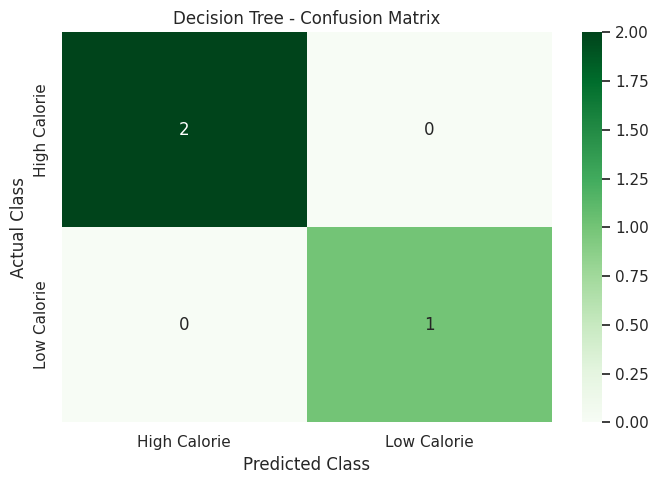

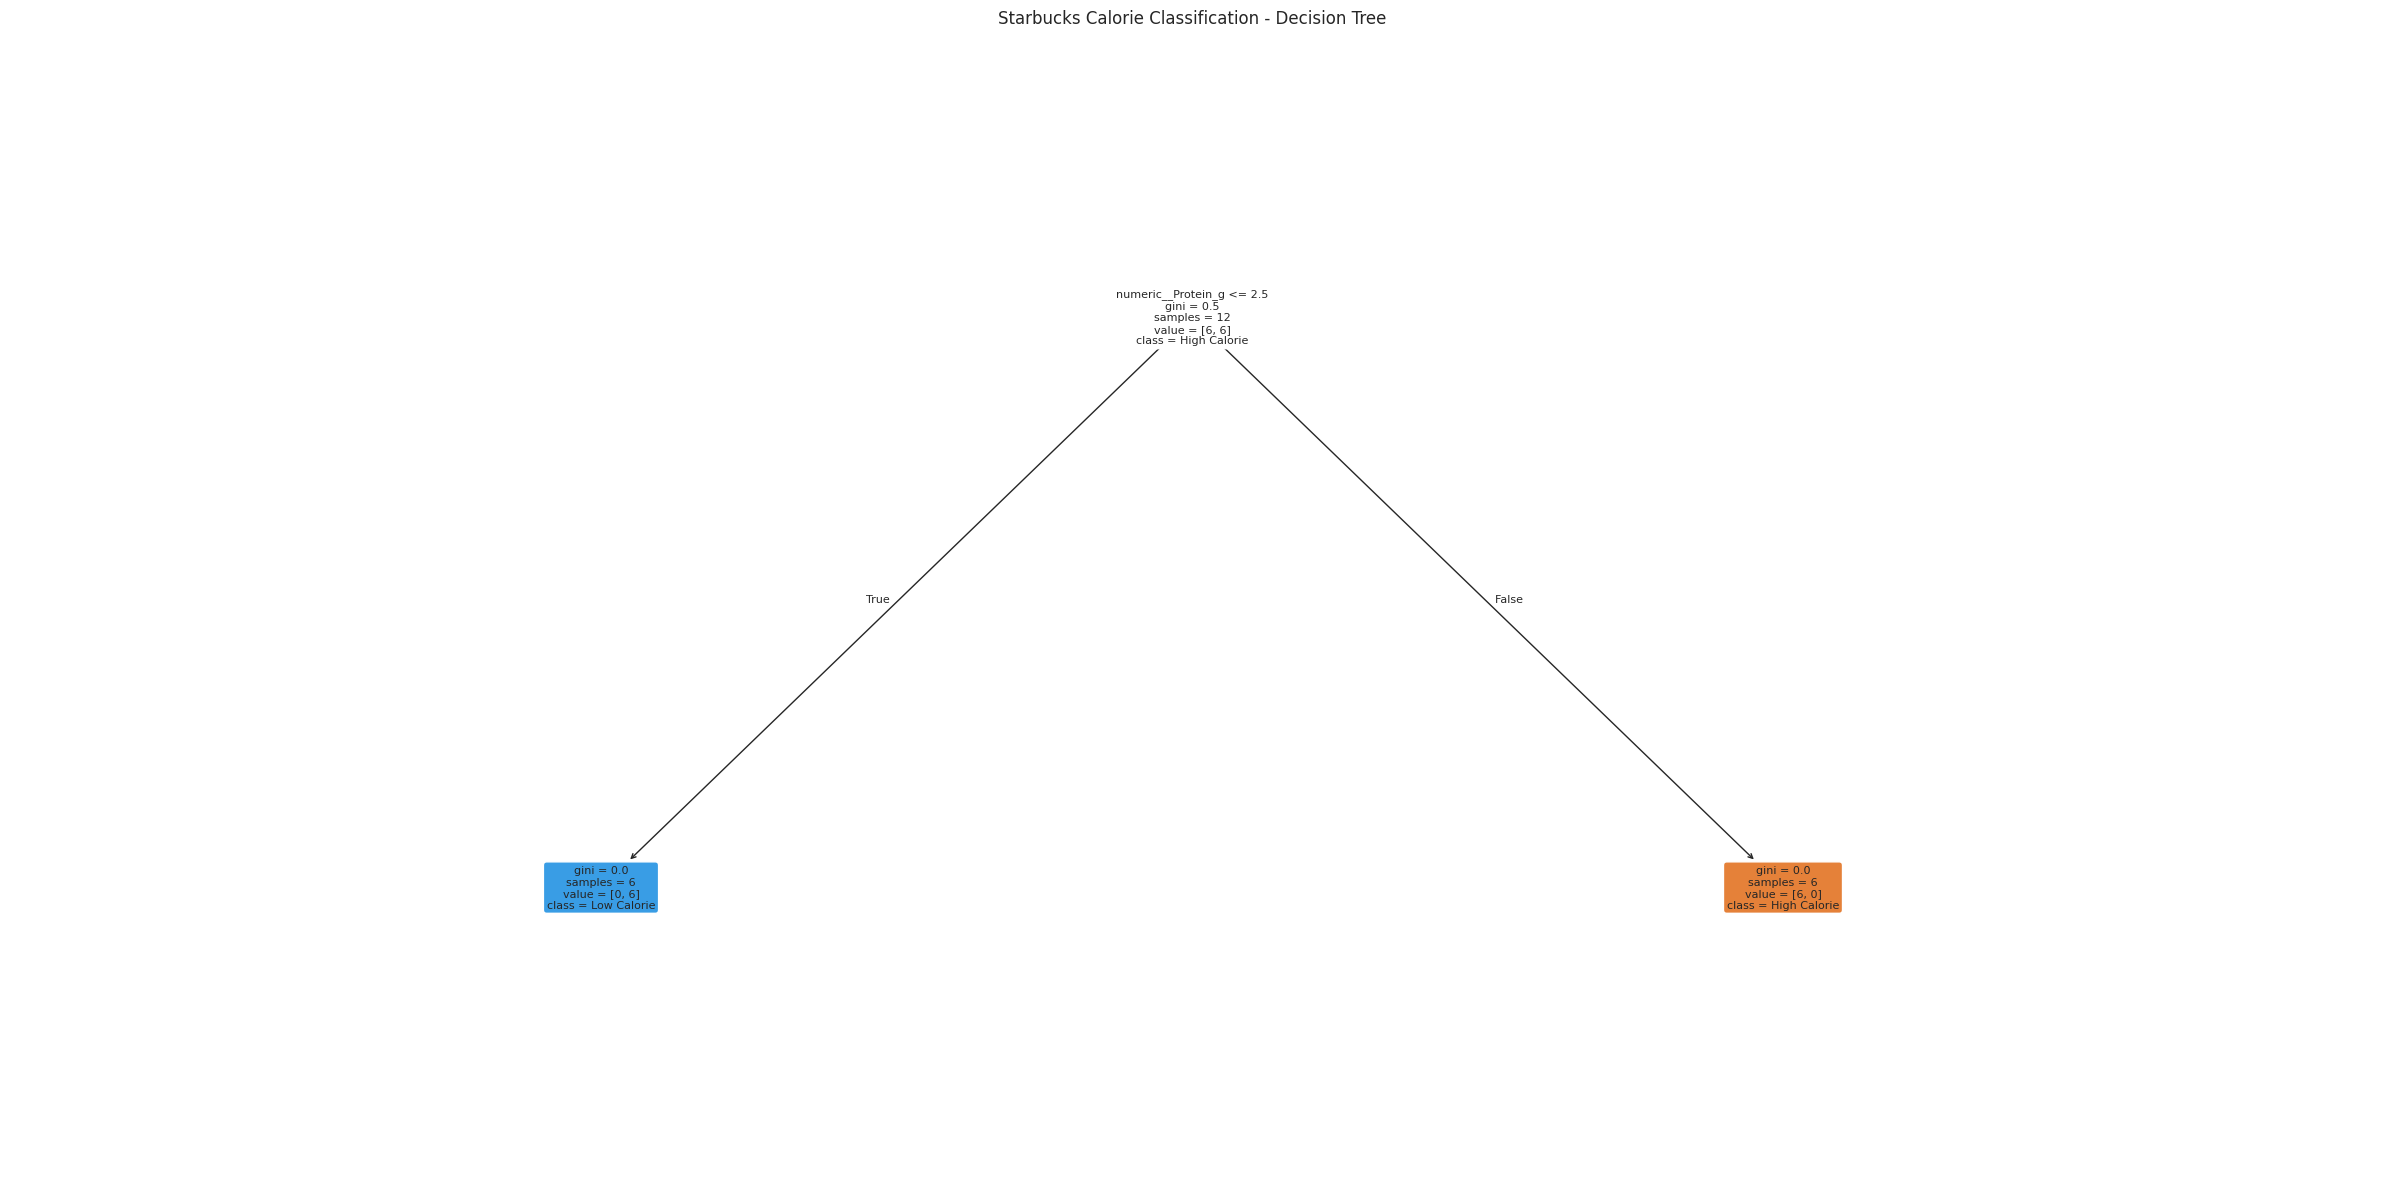

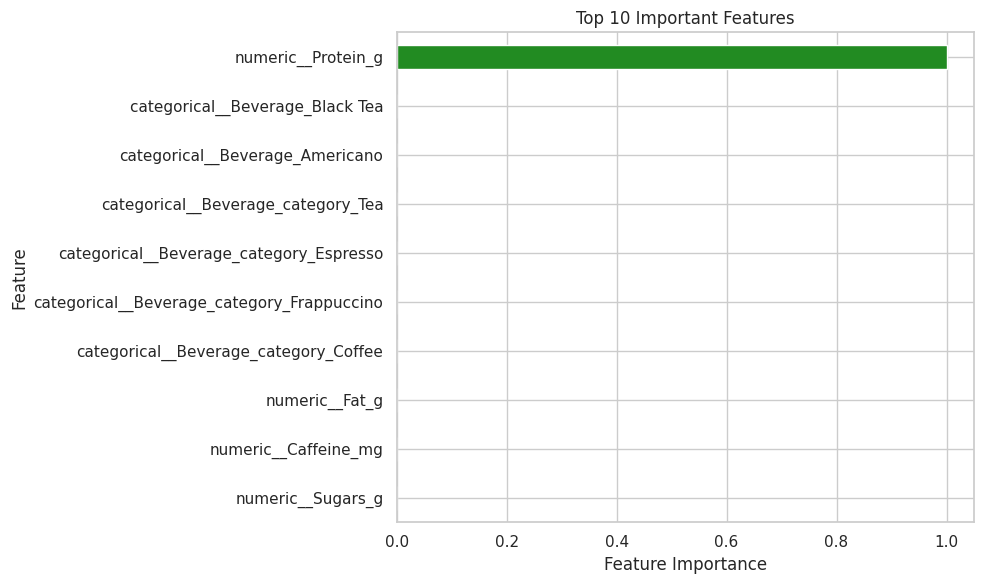


Actual vs Predicted:


,Actual Class,Predicted Class
5,High Calorie,High Calorie
12,Low Calorie,Low Calorie
13,High Calorie,High Calorie



DECISION TREE PROJECT COMPLETED
Algorithm: Decision Tree Classifier
Target: High Calorie / Low Calorie
Training samples: 12
Testing samples: 3
Accuracy: 100.00%
Decision tree graph, confusion matrix and feature importance shown.

Note: Classes are based on the dataset's median calories.
Accuracy measures performance on the held-out test set.


In [ ]:

# ============================================================
# STARBUCKS MACHINE LEARNING - DECISION TREE CLASSIFIER
# Dataset + Training + Accuracy + Graphs + Tree Visualization
# ============================================================

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

sns.set_theme(style="whitegrid")

print("=" * 60)
print(" STARBUCKS DECISION TREE MACHINE LEARNING MODEL")
print("=" * 60)

# ------------------------------------------------------------
# 1. LOAD THE STARBUCKS DATASET
# ------------------------------------------------------------

# Reuse df from the EDA cell if it exists.
# Otherwise search Kaggle input folders for a CSV.

if "df" in globals() and isinstance(df, pd.DataFrame):
    ml_df = df.copy()
    print("Using dataset already loaded in the notebook.")
else:
    csv_files = glob.glob(
        "/kaggle/input/**/*.csv", recursive=True
    )

    matches = [
        f for f in csv_files
        if "starbucks" in os.path.basename(f).lower()
    ]

    if not matches:
        raise FileNotFoundError(
            "Starbucks CSV not found. Click Add Input in Kaggle "
            "and attach your Starbucks dataset first."
        )

    preferred = [
        f for f in matches
        if "drinkmenu" in os.path.basename(f).lower()
    ]
    file_path = preferred[0] if preferred else matches[0]

    ml_df = pd.read_csv(file_path)
    print("Loaded:", file_path)

print("Dataset shape:", ml_df.shape)
display(ml_df.head())

# ------------------------------------------------------------
# 2. FIND THE CALORIES COLUMN
# ------------------------------------------------------------

calorie_cols = [
    c for c in ml_df.columns
    if "calories" in c.lower()
]

if not calorie_cols:
    raise ValueError(
        "No Calories column found. Check your dataset columns."
    )

target_col = calorie_cols[0]

# Convert target to numeric
ml_df[target_col] = pd.to_numeric(
    ml_df[target_col].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

ml_df = ml_df.dropna(subset=[target_col]).copy()

# ------------------------------------------------------------
# 3. CREATE TARGET CLASSES
# ------------------------------------------------------------

# Predict whether a drink is below or at/above the median
median_calories = ml_df[target_col].median()

ml_df["Calorie_Level"] = np.where(
    ml_df[target_col] >= median_calories,
    "High Calorie",
    "Low Calorie"
)

print("\nMedian calories:", median_calories)
print("\nTarget class distribution:")
print(ml_df["Calorie_Level"].value_counts())

# ------------------------------------------------------------
# 4. SELECT FEATURES
# ------------------------------------------------------------

# Exclude calories from input features to prevent target leakage.
# Also exclude the target and other calorie-related columns.

exclude_cols = {
    "Calorie_Level",
    target_col
}

features = ml_df.drop(
    columns=list(exclude_cols), errors="ignore"
).copy()

# Remove any other columns that contain calorie information
features = features[
    [c for c in features.columns
     if "calorie" not in c.lower()]
]

# Convert numeric-looking object columns
for col in features.columns:
    if features[col].dtype == "object":
        converted = pd.to_numeric(
            features[col].astype(str).str.replace(
                ",", "", regex=False
            ),
            errors="coerce"
        )

        nonmissing = features[col].notna().sum()

        if nonmissing and converted.notna().sum() / nonmissing >= 0.8:
            features[col] = converted

# Remove columns with no usable data
features = features.dropna(axis=1, how="all")

# Remove columns with only one unique value
features = features.loc[
    :, features.nunique(dropna=True) > 1
]

# Keep only useful numeric and categorical features
numeric_features = features.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = features.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Drop rows with missing target (already handled above)
X = features[numeric_features + categorical_features]
y = ml_df.loc[X.index, "Calorie_Level"]

if X.shape[1] == 0:
    raise ValueError(
        "No usable features found. Check the CSV columns."
    )

if y.nunique() < 2 or y.value_counts().min() < 2:
    raise ValueError(
        "Not enough records in both target classes for a "
        "stratified train/test split."
    )

print("\nNumeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Total input features:", X.shape[1])

# ------------------------------------------------------------
# 5. PREPROCESSING
# ------------------------------------------------------------

transformers = []

if numeric_features:
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])

    transformers.append(
        ("numeric", numeric_pipeline, numeric_features)
    )

if categorical_features:
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    transformers.append(
        ("categorical", categorical_pipeline, categorical_features)
    )

preprocessor = ColumnTransformer(transformers=transformers)

# ------------------------------------------------------------
# 6. SPLIT DATA INTO TRAINING AND TESTING
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))

# ------------------------------------------------------------
# 7. TRAIN DECISION TREE MODEL
# ------------------------------------------------------------

model = Pipeline([
    ("preprocessor", preprocessor),
    ("tree", DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=2,
        random_state=42,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

print("\nDecision Tree model trained successfully!")

# ------------------------------------------------------------
# 8. MAKE PREDICTIONS
# ------------------------------------------------------------

y_pred = model.predict(X_test)

# ------------------------------------------------------------
# 9. MODEL ACCURACY
# ------------------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("\n" + "=" * 45)
print("MODEL EVALUATION")
print("=" * 45)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))

# ------------------------------------------------------------
# 10. CONFUSION MATRIX GRAPH
# ------------------------------------------------------------

labels = ["High Calorie", "Low Calorie"]

cm = confusion_matrix(
    y_test, y_pred,
    labels=labels
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. VISUALIZE DECISION TREE
# ------------------------------------------------------------

fitted_preprocessor = model.named_steps["preprocessor"]
fitted_tree = model.named_steps["tree"]

try:
    feature_names = fitted_preprocessor.get_feature_names_out()
except Exception:
    feature_names = [
        f"Feature {i}"
        for i in range(fitted_tree.n_features_in_)
    ]

plt.figure(figsize=(24, 12))

plot_tree(
    fitted_tree,
    feature_names=list(feature_names),
    class_names=list(fitted_tree.classes_),
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=4
)

plt.title("Starbucks Calorie Classification - Decision Tree")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 12. FEATURE IMPORTANCE GRAPH
# ------------------------------------------------------------

importance = pd.Series(
    fitted_tree.feature_importances_,
    index=feature_names
).sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
importance.sort_values().plot(
    kind="barh",
    color="forestgreen"
)

plt.title("Top 10 Important Features")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 13. ACTUAL VS PREDICTED RESULTS
# ------------------------------------------------------------

results = pd.DataFrame({
    "Actual Class": y_test,
    "Predicted Class": y_pred
})

print("\nActual vs Predicted:")
display(results.head(15))

# ------------------------------------------------------------
# 14. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("DECISION TREE PROJECT COMPLETED")
print("=" * 60)

print("Algorithm: Decision Tree Classifier")
print("Target: High Calorie / Low Calorie")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print(f"Accuracy: {accuracy * 100:.2f}%")
print("Decision tree graph, confusion matrix and feature importance shown.")
print("\nNote: Classes are based on the dataset's median calories.")
print("Accuracy measures performance on the held-out test set.")


# ------------------------------------------------------------
# 15. SAVE TRAINED MODEL AS A PKL FILE
# ------------------------------------------------------------

import pickle

model_path = "/kaggle/working/starbucks_model.pkl"

with open(model_path, "wb") as file:
    pickle.dump(model, file)

print("\\nTrained model saved successfully:")
print(model_path)
print("In Kaggle, open the Output/Files panel to download starbucks_model.pkl.")
print("Keep this file with app.py when deploying the model.")
